In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
import pandas as pd
import os
from scipy.interpolate import InterpolatedUnivariateSpline as inspl

## Notepad para graficación básica de datos (tstability)

In [2]:
# Leyendo archivos de datos
zheng = np.genfromtxt(fname=r'C:\Users\20210015\Documents\Repos\tstability\zheng_tstability')
hu = np.genfromtxt(fname=r'C:\Users\20210015\Documents\Repos\tstability\hu_tstability.dat')
zhang = np.genfromtxt(fname=r'C:\Users\20210015\Documents\Repos\tstability\zhang_tstability2')
wu = np.genfromtxt(fname=r'C:\Users\20210015\Documents\Repos\tstability\wu_tstability2')
schmidt = np.genfromtxt(fname=r'C:\Users\20210015\Documents\Repos\tstability\schmidt_tstability2')

exp1 = np.genfromtxt(fname=r'C:\Users\20210015\Documents\ZIF8_2ndSubmission\AFTER RESUBMISSION\Changes\Including experimental data\VvsT\wu digitized\zhou.txt')

In [3]:
# Transformando
zheng = np.transpose(zheng)
hu = np.transpose(hu)
zhang = np.transpose(zhang)
wu = np.transpose(wu)
schmidt = np.transpose(schmidt)

exp1 = np.transpose(exp1)
exp2 = [258.0, 16.991]

In [4]:
# Raspa min volume (1atm, 0Pa)
raspa_zheng = 33.4219057618165*0.5
raspa_hu = 39278.1886848084
raspa_zhang = 39503.1530898870
raspa_wu = 39140.1101539154 #Not Completed Iteration 65
raspa_wu2 = 39168.112657 # fake
raspa_schmidt = 38220.7642612332

# lammps iter atoms then box
lammps_iter = 33.636563*0.5

# lammps CG with box/relax
lammps_CG = 33.909934*0.5

lammps_CG_2 = 33.785952*0.5

# lammps after 0.5K MD
lammps_md = 33.417573*0.5


In [5]:
# Volume to Lparam
zheng[1] = [0.5*((x)**(1/3)) for x in zheng[1]]
hu[1] = [0.5*((x)**(1/3)) for x in hu[1]]
zhang[4] = [0.5*((x)**(1/3)) for x in zhang[4]]
wu[4] = [0.5*((x)**(1/3)) for x in wu[4]]
schmidt[4] = [0.5*((x)**(1/3)) for x in schmidt[4]]
wu[4]

array([16.98026834, 16.97990706, 16.98015273, 16.98208898, 16.98362032,
       16.98724533, 16.99111416])

In [40]:
# RASPA vol to Lparam
raspa_hu = 0.5*((raspa_hu)**(1/3))
raspa_zhang = 0.5*((raspa_zhang)**(1/3))
raspa_wu = 0.5*((raspa_wu)**(1/3))
raspa_wu2 = 0.5*((raspa_wu2)**(1/3))
raspa_schmidt = 0.5*((raspa_schmidt)**(1/3))

In [41]:
# Spline (zheng main)
where = 0
order = 1
spline = inspl(zheng[0], zheng[1], k=order)
sticks = np.linspace(0, 1050, 5000)
value0 = spline(where)
svals = spline(sticks)
print(value0)

16.716241887520845


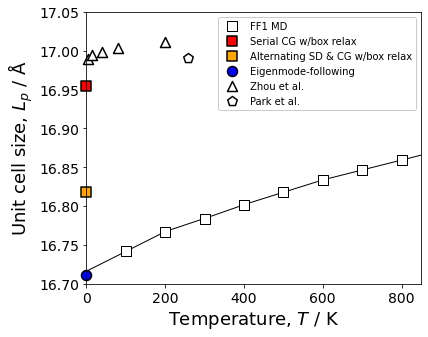

In [42]:
# Plotting FF (manuscript)
fig = plt.figure()
fig.set_size_inches(6.0, 5.0, forward=True)
plt.xlabel(r"Temperature, $T$ / $\mathrm{K}$", fontsize=18)
plt.ylabel(r"Unit cell size, $L_{p}$ / $\mathrm{\AA}$", fontsize=18)

plt.axis([0.0, 850, 16.7, 17.05])
plt.xticks(np.arange(0.0, 850, 200), fontsize=14)
plt.yticks(np.arange(16.7, 17.05, 0.05), fontsize=14)

# a[0], a[1], marker='o', color='red', edgecolor='black', linewidth=1, s=90, label='FF1', zorder=2
plt.scatter(zheng[0], zheng[1], marker='s', color='white', edgecolor='black', linewidth=1, s=100, zorder=2, label='FF1 MD')
plt.plot(sticks, svals, zorder=1, color='black', linewidth=1)
plt.scatter(0, lammps_CG, clip_on=False, marker='s', color='red', edgecolor='black', linewidth=1.5, s=90, zorder=2, label='Serial CG w/box relax')
#plt.scatter(0, lammps_CG_2, clip_on=False, marker='s', color='orange', edgecolor='black', linewidth=1.5, s=100, zorder=2, label='Serial CG w/box relax')
plt.scatter(0, lammps_iter, clip_on=False, marker='s', color='orange', edgecolor='black', linewidth=1.5, s=100, zorder=2, label='Alternating SD & CG w/box relax')
plt.scatter(0, raspa_zheng, marker='o', clip_on=False, color='blue', edgecolor='black', linewidth=1.5, s=100, zorder=2, label='Eigenmode-following')
#plt.scatter(0, lammps_md, marker='s', clip_on=False, facecolors='none', edgecolor='red', linewidth=1.5, s=100, zorder=2)
#experimentals:
plt.scatter(exp1[0], exp1[1], marker='^', clip_on=False, color='white', edgecolor='black', linewidth=1.5, s=100, zorder=2, label='Zhou et al.')
plt.scatter(exp2[0], exp2[1], marker='p', clip_on=False, color='white', edgecolor='black', linewidth=1.5, s=100, zorder=2, label='Park et al.')


plt.legend(facecolor='white', fontsize=10, framealpha=1)
# plt.grid(True, linestyle='--')
fig.savefig(r'C:\Users\20210015\Documents\ZIF8_2ndSubmission\AFTER RESUBMISSION\Changes\Including experimental data\VvsT\plots\zheng_tstab_new.png', bbox_inches='tight', dpi=500)
fig.savefig(r'C:\Users\20210015\Documents\ZIF8_2ndSubmission\AFTER RESUBMISSION\Changes\Including experimental data\VvsT\plots\zheng_tstab_new.pdf', bbox_inches='tight')

plt.show()

In [62]:
# Spline (all others ESI)... All FFs order 1, schmidt order 3
where = 0
order = 3
spline = inspl(schmidt[0], schmidt[4], k=order)
sticks2 = np.linspace(0, 1050, 5000)
value0 = spline(where)
svals2 = spline(sticks2)
print(value0)

16.84862187743371


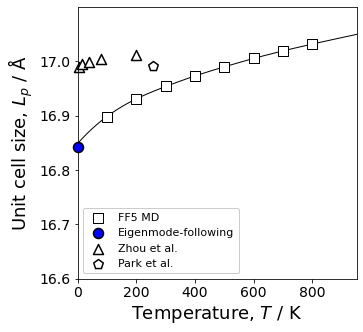

In [63]:
# Plotting FF (ESI)
fig = plt.figure()
fig.set_size_inches(5.0, 5.0, forward=True)
plt.xlabel(r"Temperature, $T$ / $\mathrm{K}$", fontsize=18)
plt.ylabel(r"Unit cell size, $L_{p}$ / $\mathrm{\AA}$", fontsize=18)

plt.axis([0.0, 950, 16.6, 17.10])
plt.xticks(np.arange(0.0, 950, 200), fontsize=14)
plt.yticks(np.arange(16.6, 17.1, 0.1), fontsize=14)

# a[0], a[1], marker='o', color='red', edgecolor='black', linewidth=1, s=90, label='FF1', zorder=2
plt.scatter(schmidt[0], schmidt[4], marker='s', color='white', edgecolor='black', linewidth=1, s=100, zorder=2, label='FF5 MD')
plt.plot(sticks2, svals2, zorder=1, color='black', linewidth=1)
#plt.scatter(0, lammps_CG, clip_on=False, marker='s', color='red', edgecolor='black', linewidth=1.5, s=90, zorder=2, label='Serial CG w/box relax')
#plt.scatter(0, lammps_CG_2, clip_on=False, marker='s', color='orange', edgecolor='black', linewidth=1.5, s=100, zorder=2, label='Serial CG w/box relax')
#plt.scatter(0, lammps_iter, clip_on=False, marker='s', color='orange', edgecolor='black', linewidth=1.5, s=100, zorder=2, label='Alternating SD & CG w/box relax')
plt.scatter(0, raspa_schmidt, marker='o', clip_on=False, color='blue', edgecolor='black', linewidth=1.5, s=100, zorder=3, label='Eigenmode-following')
#plt.scatter(0, lammps_md, marker='s', clip_on=False, facecolors='none', edgecolor='red', linewidth=1.5, s=100, zorder=2)
#experimentals:
plt.scatter(exp1[0], exp1[1], marker='^', clip_on=False, color='white', edgecolor='black', linewidth=1.5, s=100, zorder=2, label='Zhou et al.')
plt.scatter(exp2[0], exp2[1], marker='p', clip_on=False, color='white', edgecolor='black', linewidth=1.5, s=100, zorder=2, label='Park et al.')


plt.legend(facecolor='white', fontsize=11, framealpha=1)
# plt.grid(True, linestyle='--')
fig.savefig(r'C:\Users\20210015\Documents\ZIF8_2ndSubmission\AFTER RESUBMISSION\Changes\Including experimental data\VvsT\plots\schmidt_tstab_new2.png', bbox_inches='tight', dpi=500)
fig.savefig(r'C:\Users\20210015\Documents\ZIF8_2ndSubmission\AFTER RESUBMISSION\Changes\Including experimental data\VvsT\plots\schmidt_tstab_new2.pdf', bbox_inches='tight')

plt.show()